In [253]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

In [254]:
df = pd.read_csv('weatherAUS.csv')
df = df.dropna()
df.drop(['Date'], axis=1, inplace=True)
df.head()

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
6049,Cobar,17.9,35.2,0.0,12.0,12.3,SSW,48.0,ENE,SW,...,20.0,13.0,1006.3,1004.4,2.0,5.0,26.6,33.4,No,No
6050,Cobar,18.4,28.9,0.0,14.8,13.0,S,37.0,SSE,SSE,...,30.0,8.0,1012.9,1012.1,1.0,1.0,20.3,27.0,No,No
6052,Cobar,19.4,37.6,0.0,10.8,10.6,NNE,46.0,NNE,NNW,...,42.0,22.0,1012.3,1009.2,1.0,6.0,28.7,34.9,No,No
6053,Cobar,21.9,38.4,0.0,11.4,12.2,WNW,31.0,WNW,WSW,...,37.0,22.0,1012.7,1009.1,1.0,5.0,29.1,35.6,No,No
6054,Cobar,24.2,41.0,0.0,11.2,8.4,WNW,35.0,NW,WNW,...,19.0,15.0,1010.7,1007.4,1.0,6.0,33.6,37.6,No,No


In [255]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56420 entries, 6049 to 142302
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Location       56420 non-null  object 
 1   MinTemp        56420 non-null  float64
 2   MaxTemp        56420 non-null  float64
 3   Rainfall       56420 non-null  float64
 4   Evaporation    56420 non-null  float64
 5   Sunshine       56420 non-null  float64
 6   WindGustDir    56420 non-null  object 
 7   WindGustSpeed  56420 non-null  float64
 8   WindDir9am     56420 non-null  object 
 9   WindDir3pm     56420 non-null  object 
 10  WindSpeed9am   56420 non-null  float64
 11  WindSpeed3pm   56420 non-null  float64
 12  Humidity9am    56420 non-null  float64
 13  Humidity3pm    56420 non-null  float64
 14  Pressure9am    56420 non-null  float64
 15  Pressure3pm    56420 non-null  float64
 16  Cloud9am       56420 non-null  float64
 17  Cloud3pm       56420 non-null  float64
 18  Temp9am

In [256]:
categorical_columns = df.select_dtypes(include=['object']).columns.drop('Location')
categorical_columns

Index(['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow'], dtype='object')

In [257]:
one_hot = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
preprocessor = ColumnTransformer(
    transformers=[('cat', one_hot, categorical_columns)],
    remainder='passthrough'
)
data = preprocessor.fit_transform(df)
df = pd.DataFrame(data, columns=preprocessor.get_feature_names_out())

float_cat = ['cat__WindGustDir_E', 'cat__WindGustDir_ENE', 'cat__WindGustDir_ESE',
       'cat__WindGustDir_N', 'cat__WindGustDir_NE', 'cat__WindGustDir_NNE',
       'cat__WindGustDir_NNW', 'cat__WindGustDir_NW', 'cat__WindGustDir_S',
       'cat__WindGustDir_SE', 'cat__WindGustDir_SSE', 'cat__WindGustDir_SSW',
       'cat__WindGustDir_SW', 'cat__WindGustDir_W', 'cat__WindGustDir_WNW',
       'cat__WindGustDir_WSW', 'cat__WindDir9am_E', 'cat__WindDir9am_ENE',
       'cat__WindDir9am_ESE', 'cat__WindDir9am_N', 'cat__WindDir9am_NE',
       'cat__WindDir9am_NNE', 'cat__WindDir9am_NNW', 'cat__WindDir9am_NW',
       'cat__WindDir9am_S', 'cat__WindDir9am_SE', 'cat__WindDir9am_SSE',
       'cat__WindDir9am_SSW', 'cat__WindDir9am_SW', 'cat__WindDir9am_W',
       'cat__WindDir9am_WNW', 'cat__WindDir9am_WSW', 'cat__WindDir3pm_E',
       'cat__WindDir3pm_ENE', 'cat__WindDir3pm_ESE', 'cat__WindDir3pm_N',
       'cat__WindDir3pm_NE', 'cat__WindDir3pm_NNE', 'cat__WindDir3pm_NNW',
       'cat__WindDir3pm_NW', 'cat__WindDir3pm_S', 'cat__WindDir3pm_SE',
       'cat__WindDir3pm_SSE', 'cat__WindDir3pm_SSW', 'cat__WindDir3pm_SW',
       'cat__WindDir3pm_W', 'cat__WindDir3pm_WNW', 'cat__WindDir3pm_WSW',
       'cat__RainToday_No', 'cat__RainToday_Yes', 'cat__RainTomorrow_No',
       'cat__RainTomorrow_Yes', 'remainder__MinTemp',
       'remainder__MaxTemp', 'remainder__Rainfall', 'remainder__Evaporation',
       'remainder__Sunshine', 'remainder__WindGustSpeed',
       'remainder__WindSpeed9am', 'remainder__WindSpeed3pm',
       'remainder__Humidity9am', 'remainder__Humidity3pm',
       'remainder__Pressure9am', 'remainder__Pressure3pm',
       'remainder__Cloud9am', 'remainder__Cloud3pm', 'remainder__Temp9am',
       'remainder__Temp3pm']
df[float_cat] = df[float_cat].astype(float)

In [258]:
learn_df = df[df.remainder__Location == 'Williamtown'].drop(['cat__RainTomorrow_No', 'cat__RainToday_No'], axis=1)
y = learn_df['cat__RainTomorrow_Yes'].values
y[y == 0] = -1
X = learn_df.drop(['remainder__Location', 'cat__RainTomorrow_Yes'], axis=1).values
y, X

(array([-1., -1., -1., ..., -1., -1., -1.]),
 array([[ 0. ,  0. ,  0. , ...,  6. , 23.7, 28.7],
        [ 0. ,  0. ,  0. , ...,  2. , 21.6, 23.4],
        [ 0. ,  0. ,  0. , ...,  7. , 20.1, 21.7],
        ...,
        [ 0. ,  0. ,  0. , ...,  2. , 20.7, 21.3],
        [ 0. ,  0. ,  0. , ...,  2. , 17.6, 21.9],
        [ 0. ,  0. ,  1. , ...,  1. , 19. , 22.5]]))

In [259]:
new_df = df[df.remainder__Location == 'Watsonia'].drop(['cat__RainTomorrow_No', 'cat__RainToday_No'], axis=1)
newy = new_df['cat__RainTomorrow_Yes'].values
newy[newy == 0] = -1
newX = new_df.drop(['remainder__Location', 'cat__RainTomorrow_Yes'], axis=1).values
newy, newX

(array([-1., -1., -1., ...,  1., -1., -1.]),
 array([[ 0. ,  0. ,  0. , ...,  7. , 16.9, 18. ],
        [ 0. ,  0. ,  0. , ...,  7. , 11.7, 17.1],
        [ 0. ,  0. ,  0. , ...,  7. , 12.9, 19.9],
        ...,
        [ 0. ,  0. ,  0. , ...,  7. ,  8.8, 11.6],
        [ 0. ,  0. ,  0. , ...,  7. ,  7.9, 11. ],
        [ 0. ,  0. ,  0. , ...,  7. ,  9. , 11.7]]))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

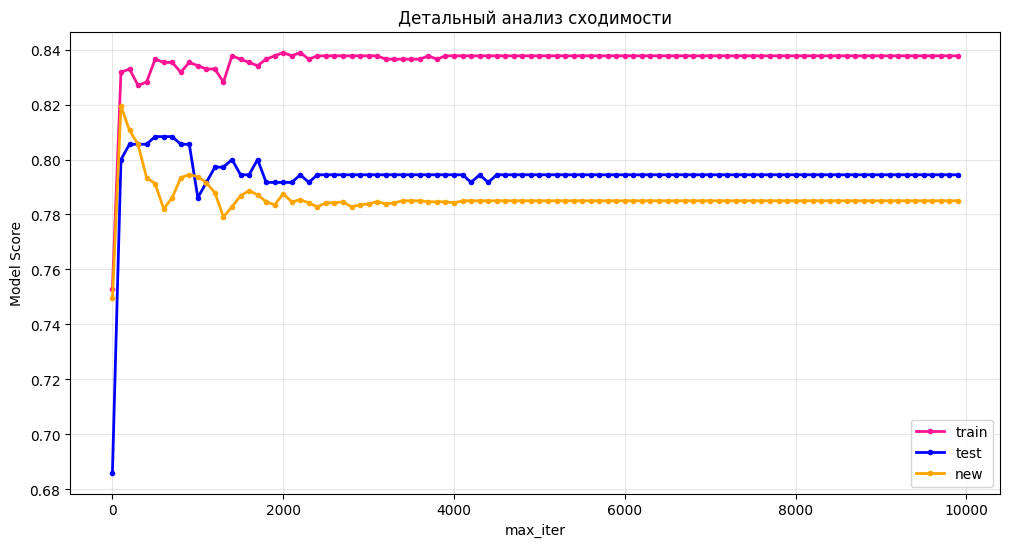

In [262]:
scores_detailed_train = []
scores_detailed_test = []
scores_detailed_new = []

for max_iter in range(1, 10000, 100):
    xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=8)
    model = LogisticRegression(fit_intercept=False, max_iter=max_iter, random_state=8)
    model.fit(xtrain, ytrain)
    scores_detailed_train.append(model.score(xtrain, ytrain))
    scores_detailed_test.append(model.score(xtest, ytest))
    scores_detailed_new.append(model.score(newX, newy))

plt.figure(figsize=(12, 6))
plt.plot(range(1, 10000, 100), scores_detailed_train, marker='o', linewidth=2, markersize=3, color='deeppink', label="train")
plt.plot(range(1, 10000, 100), scores_detailed_test, marker='o', linewidth=2, markersize=3, color='blue', label="test")
plt.plot(range(1, 10000, 100), scores_detailed_new, marker='o', linewidth=2, markersize=3, color='orange', label="new")
plt.xlabel('max_iter')
plt.ylabel('Model Score')
plt.title('Детальный анализ сходимости')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## остановимся на 3000 итерациях

In [264]:
xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=8)
model = LogisticRegression(fit_intercept=False, max_iter=3000, random_state=8)
model.fit(xtrain, ytrain)
print(f"Train {model.score(xtrain, ytrain)}")
print(f"Test {model.score(xtest, ytest)}")
print(f"Region-2 score {model.score(newX, newy)}")

Train 0.837708830548926
Test 0.7944444444444444
Region-2 score 0.7838827838827839


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
